In [1]:
# -------------------------------------------------------------------------
# 0. Dependencies Installation
# -------------------------------------------------------------------------
!pip install torchxrayvision --no-deps -q
!pip install pandas numpy matplotlib seaborn wordcloud scikit-image scikit-learn -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.0/29.0 MB 35.9 MB/s eta 0:00:0000:0100:01


In [2]:
# -------------------------------------------------------------------------
# 1. PhysioNet Login & Dataset Indexing
# -------------------------------------------------------------------------
import os, sys, subprocess, pandas as pd, numpy as np
from pathlib import Path

work_dir = "/kaggle/working"
os.makedirs(work_dir, exist_ok=True)
os.chdir(work_dir)

# PhysioNet Credentials (edit or use Kaggle Secrets)
try:
    from kaggle_secrets import UserSecretsClient
    user_secrets = UserSecretsClient()
    PHYSIONET_USER = user_secrets.get_secret("PHYSIONET_USER")
    PHYSIONET_PASS = user_secrets.get_secret("PHYSIONET_PASS")
except Exception:
    PHYSIONET_USER = os.environ.get("PHYSIONET_USER", "")
    PHYSIONET_PASS = os.environ.get("PHYSIONET_PASS", "")

netrc_content = "machine physionet.org\nlogin " + str(PHYSIONET_USER) + "\npassword " + str(PHYSIONET_PASS) + "\n"
netrc_path = os.path.expanduser("~/.netrc")
with open(netrc_path, "w", encoding="utf-8") as f:
    f.write(netrc_content)
os.chmod(netrc_path, 0o600)

metadata_files = [
    ("meta.csv", "https://physionet.org/files/mimic-cxr-jpg/2.1.0/mimic-cxr-2.0.0-metadata.csv.gz"),
    ("chexpert.csv", "https://physionet.org/files/mimic-cxr-jpg/2.1.0/mimic-cxr-2.0.0-chexpert.csv.gz"),
]

for target_name, url in metadata_files:
    if not os.path.exists(target_name):
        gz_name = target_name + ".gz"
        print(f"Downloading {target_name}...")
        subprocess.run("wget -q --netrc -O " + gz_name + " " + url, shell=True, check=True)
        subprocess.run("gunzip -f " + gz_name, shell=True, check=True)

print("Indexing Kaggle local images...")
input_base = Path("/kaggle/input")
file_index = {}
impression_file_paths = []

for root, _, files in os.walk(input_base):
    for f in files:
        full_path = os.path.join(root, f)
        if f in ["mimic_train_impressions.csv", "train_imp.csv", "mimic_test_impressions.csv", "test_imp.csv"]:
            if full_path not in impression_file_paths:
                impression_file_paths.append(full_path)
        elif f.endswith(".jpg"):
            parts = full_path.split("/")
            rel_path = None
            for prefix in ("p10", "p11"):
                if prefix in parts:
                    idx = parts.index(prefix)
                    rel_path = "/".join(parts[idx:])
                    break
            if rel_path is not None and rel_path not in file_index:
                file_index[rel_path] = full_path

print(f"Completed Indexing. Found {len(file_index)} images on disk.")
if not impression_file_paths:
    print("Warning: No impressions CSV files found. Please make sure impressions dataset is attached.")


Indexing Kaggle local images...
Completed Indexing. Found 73995 images on disk.


In [7]:
# -------------------------------------------------------------------------
# 2. Cohort Filtering & Splitting (Data Leakage Verification)
# -------------------------------------------------------------------------
import pandas as pd, numpy as np
from sklearn.model_selection import GroupShuffleSplit

report_dfs = [pd.read_csv(p) for p in impression_file_paths]
report_df = pd.concat(report_dfs, ignore_index=True).drop_duplicates(subset=["dicom_id"])

meta_df = pd.read_csv("meta.csv")
chex_df = pd.read_csv("chexpert.csv")

# Exclude metadata missing in chexpert
chex_label_cols = [c for c in chex_df.columns if c not in ["subject_id", "study_id"]]
for c in chex_label_cols:
    chex_df[c] = chex_df[c].fillna(0.0)
    chex_df[c] = chex_df[c].replace(-1.0, 0.0)

# Filter cohort
mask_cohort = (meta_df["subject_id"] >= 10000000) & (meta_df["subject_id"] < 12000000)
meta_cohort = meta_df[mask_cohort].copy()

# Merges
merged_df = pd.merge(meta_cohort, chex_df[["study_id"] + chex_label_cols], on="study_id", how="inner")
merged_df = pd.merge(merged_df, report_df[["dicom_id", "report"]], on="dicom_id", how="left")
merged_df = merged_df.dropna(subset=["report"]).reset_index(drop=True)

def get_path(row):
    subject_id = int(row["subject_id"])
    study_id = int(row["study_id"])
    prefix = "p10" if subject_id < 11000000 else "p11"
    rel = prefix + "/p" + str(subject_id) + "/s" + str(study_id) + "/" + str(row["dicom_id"]) + ".jpg"
    return file_index.get(rel, None)

merged_df["image_path"] = merged_df.apply(get_path, axis=1)
# NOTE: Do NOT dropna here, so text/prevalence stats run even if image datasets are not attached yet!
merged_df = merged_df.reset_index(drop=True)

print(f"Cohort Matched Samples: {len(merged_df)}")
print(f"Unique Subjects (Patients): {merged_df['subject_id'].nunique()}")

# Split
np.random.seed(42)
gss_train = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, temp_idx = next(gss_train.split(merged_df, groups=merged_df["subject_id"]))

train_df = merged_df.iloc[train_idx].copy()
temp_df = merged_df.iloc[temp_idx].copy()

gss_val = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_idx, test_idx = next(gss_val.split(temp_df, groups=temp_df["subject_id"]))

train_df = train_df.reset_index(drop=True)
val_df = temp_df.iloc[val_idx].reset_index(drop=True)
test_df = temp_df.iloc[test_idx].reset_index(drop=True)

# Data Leakage Validation
train_pats = set(train_df["subject_id"])
val_pats = set(val_df["subject_id"])
test_pats = set(test_df["subject_id"])

overlap_train_val = len(train_pats.intersection(val_pats))
overlap_train_test = len(train_pats.intersection(test_pats))
overlap_val_test = len(val_pats.intersection(test_pats))

print("-" * 50)
print(f"Train Set: {len(train_df)} images | {len(train_pats)} patients")
print(f"Val Set:   {len(val_df)} images | {len(val_pats)} patients")
print(f"Test Set:  {len(test_df)} images | {len(test_pats)} patients")
print("-" * 50)
print(f"Patient Overlap Train-Val:  {overlap_train_val} (Leakage: {overlap_train_val > 0})")
print(f"Patient Overlap Train-Test: {overlap_train_test} (Leakage: {overlap_train_test > 0})")
print(f"Patient Overlap Val-Test:   {overlap_val_test} (Leakage: {overlap_val_test > 0})")
print("-" * 50)

Cohort Matched Samples: 63816
Unique Subjects (Patients): 12385
--------------------------------------------------
Train Set: 51835 images | 9908 patients
Val Set:   6153 images | 1238 patients
Test Set:  5828 images | 1239 patients
--------------------------------------------------
Patient Overlap Train-Val:  0 (Leakage: False)
Patient Overlap Train-Test: 0 (Leakage: False)
Patient Overlap Val-Test:   0 (Leakage: False)
--------------------------------------------------


=== Cohort Pathology Prevalence ===
                 Pathology  Train Pos  Val Pos  Test Pos  Total Pos  Prevalence (%)
                No Finding      20785     2516      2697      25998           41.43
          Pleural Effusion       9334     1129      1233      11696           18.64
           Support Devices       9223     1260      1150      11633           18.54
              Lung Opacity       8913     1126      1090      11129           17.73
              Cardiomegaly       7563      943       937       9443           15.05
               Atelectasis       7540      949       933       9422           15.01
                     Edema       4854      581       542       5977            9.52
                 Pneumonia       3367      424       415       4206            6.70
             Consolidation       1783      247       239       2269            3.62
              Pneumothorax       1661      236       282       2179            3.47
               Lung Lesion       1377   

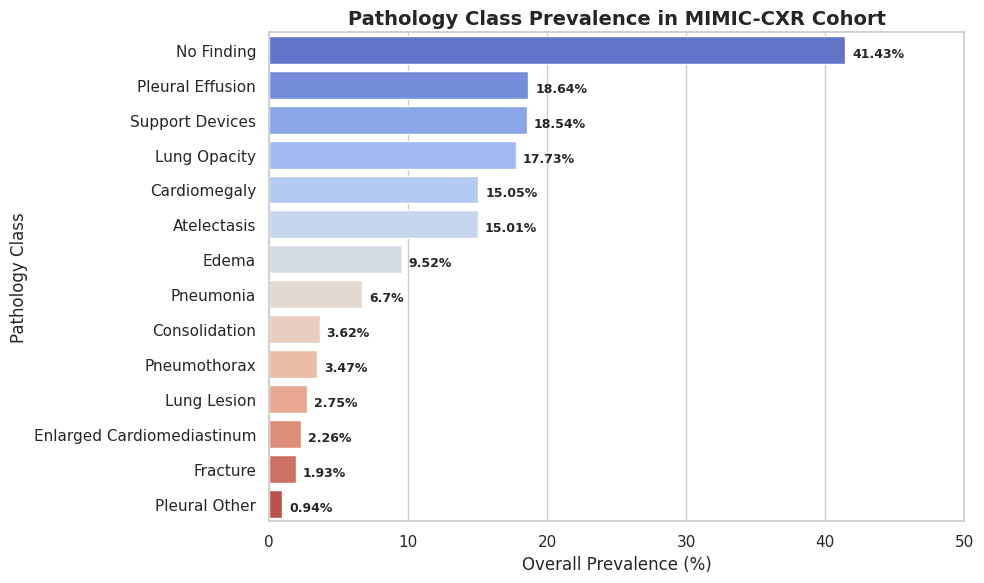

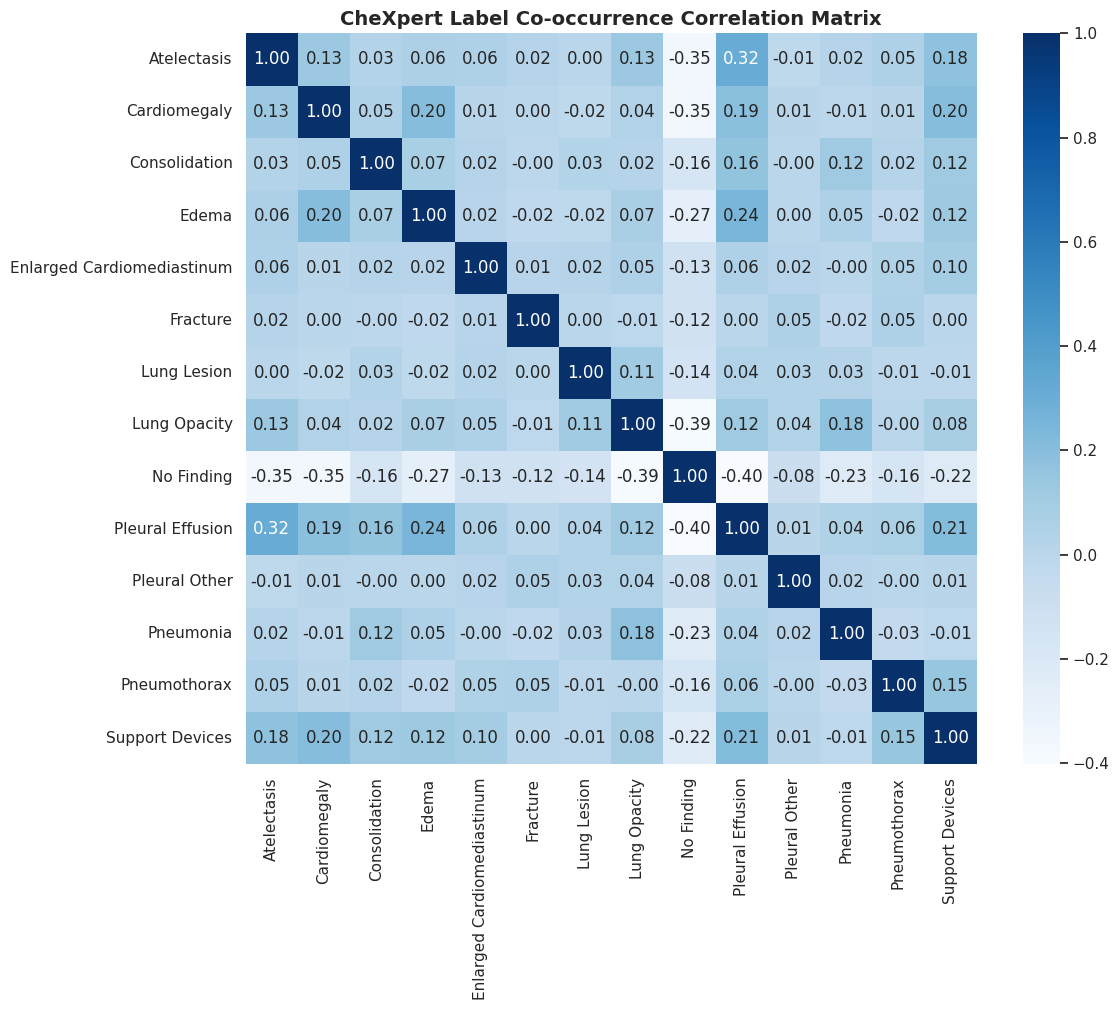

In [5]:
# -------------------------------------------------------------------------
# 3. Clinical Label Distribution & Pathology Co-occurrence Analysis
# -------------------------------------------------------------------------
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Prevalence Table
prevalence_data = []
for c in chex_label_cols:
    train_pos = int(train_df[c].sum())
    val_pos = int(val_df[c].sum())
    test_pos = int(test_df[c].sum())
    total_pos = train_pos + val_pos + test_pos
    prev = (total_pos / len(merged_df)) * 100
    prevalence_data.append({
        "Pathology": c,
        "Train Pos": train_pos,
        "Val Pos": val_pos,
        "Test Pos": test_pos,
        "Total Pos": total_pos,
        "Prevalence (%)": round(prev, 2)
    })

prev_df = pd.DataFrame(prevalence_data).sort_values(by="Prevalence (%)", ascending=False)
print("=== Cohort Pathology Prevalence ===")
print(prev_df.to_string(index=False))

# Plot 1: Prevalence Horizontal Bar Plot
plt.figure(figsize=(10, 6))
colors = sns.color_palette("coolwarm", len(prev_df))
# FIX: Assigned 'Pathology' to 'hue' and set 'legend=False' to resolve FutureWarning
ax = sns.barplot(x="Prevalence (%)", y="Pathology", data=prev_df, hue="Pathology", palette=colors, legend=False)
plt.title("Pathology Class Prevalence in MIMIC-CXR Cohort", fontweight='bold', fontsize=14)
plt.xlabel("Overall Prevalence (%)")
plt.ylabel("Pathology Class")
for i, p in enumerate(prev_df["Prevalence (%)"]):
    ax.text(p + 0.5, i + 0.1, f"{p}%", fontsize=9, va='center', fontweight='semibold')
plt.xlim(0, 50)
plt.tight_layout()
plt.savefig("cohort_prevalence.png", dpi=300)
plt.show()

# Plot 2: Pathology Co-occurrence Heatmap
label_corr = merged_df[chex_label_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(label_corr, annot=True, fmt=".2f", cmap="Blues", cbar=True, square=True)
plt.title("CheXpert Label Co-occurrence Correlation Matrix", fontweight='bold', fontsize=14)
plt.tight_layout()
plt.savefig("pathology_cooccurrence.png", dpi=300)
plt.show()

=== Text Corpus Summary ===
Average Report Length: 21.4 words (Std: 21.7)
Median Report Length:  13.0 words
Max Report Length:     229 words
Min Report Length:     1 words


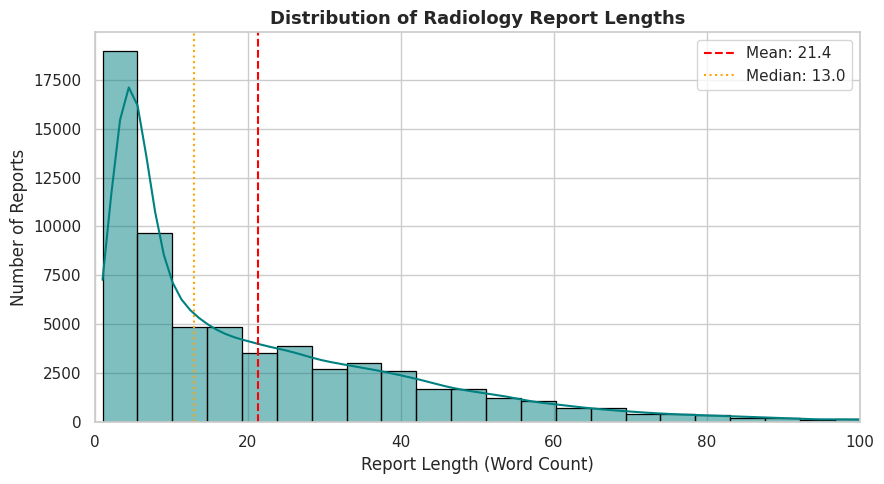

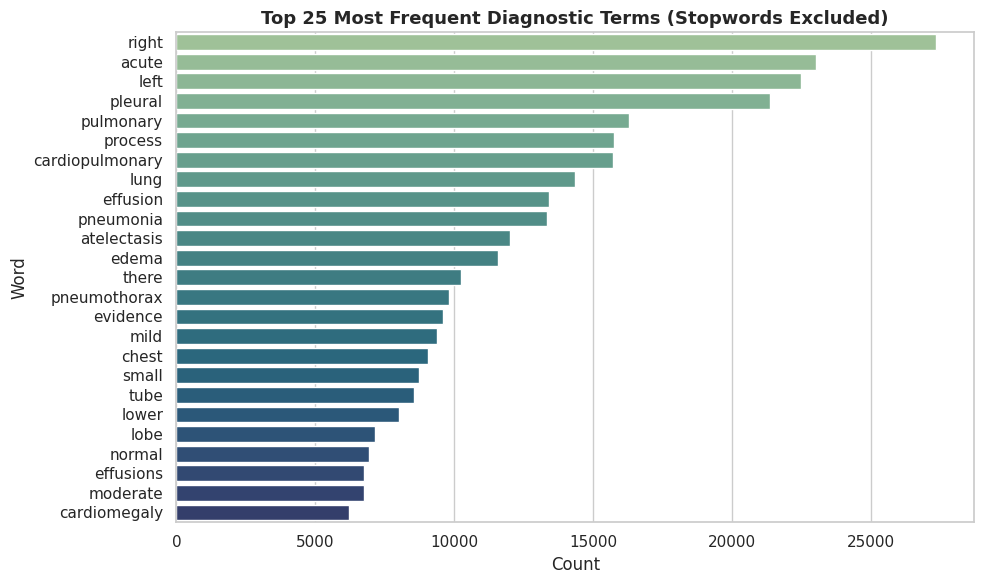

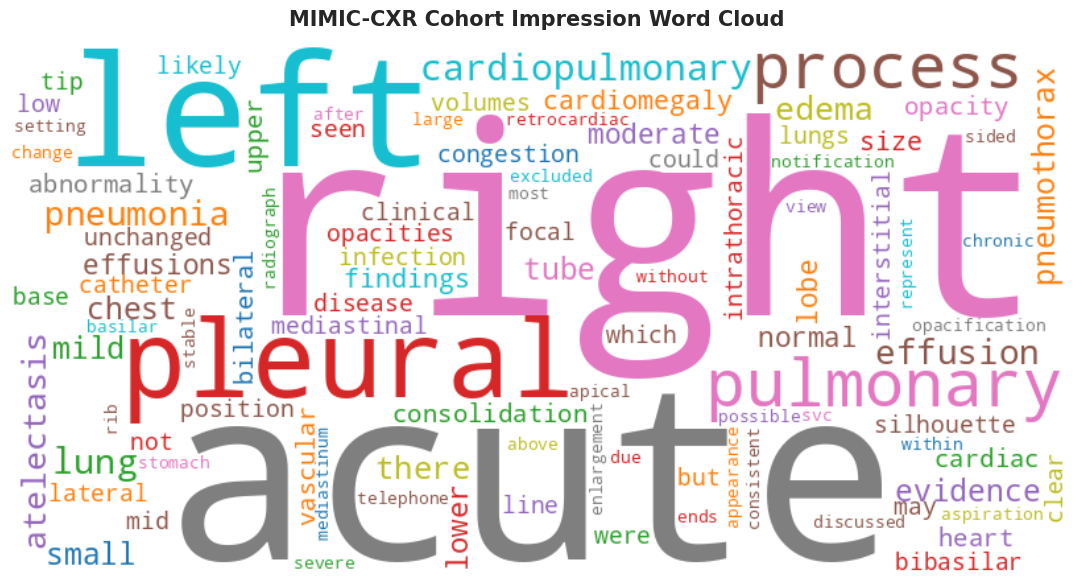

=== Diagnostic Text Negation Statistics ===
Clinical Condition  Total Mentions  Positive Mentions  Negated Mentions  Negation Rate (%)
      pneumothorax            9919               2722              7197               72.6
          effusion           20182              16528              3654               18.1
         pneumonia           13377               7787              5590               41.8
      cardiomegaly            6206               6124                82                1.3
             edema           11580               7925              3655               31.6


In [11]:
# -------------------------------------------------------------------------
# 4. Textual Corpus Analysis & Negation Distribution Statistics
# -------------------------------------------------------------------------
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import re

report_lengths = merged_df["report"].apply(lambda x: len(str(x).split()))
print(f"=== Text Corpus Summary ===")
print(f"Average Report Length: {report_lengths.mean():.1f} words (Std: {report_lengths.std():.1f})")
print(f"Median Report Length:  {report_lengths.median()} words")
print(f"Max Report Length:     {report_lengths.max()} words")
print(f"Min Report Length:     {report_lengths.min()} words")

# Plot 3: Report Word Count Distribution
plt.figure(figsize=(9, 5))
sns.histplot(report_lengths, bins=50, kde=True, color="teal", edgecolor="black")
plt.axvline(report_lengths.mean(), color="red", linestyle="dashed", linewidth=1.5, label=f"Mean: {report_lengths.mean():.1f}")
plt.axvline(report_lengths.median(), color="orange", linestyle="dotted", linewidth=1.5, label=f"Median: {report_lengths.median():.1f}")
plt.xlabel("Report Length (Word Count)")
plt.ylabel("Number of Reports")
plt.title("Distribution of Radiology Report Lengths", fontweight='bold', fontsize=13)
plt.xlim(0, 100)
plt.legend()
plt.tight_layout()
plt.savefig("report_length_distribution.png", dpi=300)
plt.show()

# Stopwords removal and word frequency count
stopwords = set(["the", "and", "of", "to", "is", "in", "for", "with", "on", "are", "at", "as", "by", "an", "be", "this", "that", "from", "or", "patient"])
all_text = " ".join(merged_df["report"].astype(str).tolist()).lower()
words = re.findall(r"\b[a-zA-Z]{3,15}\b", all_text)
filtered_words = [w for w in words if w not in stopwords]

from collections import Counter
word_freq = Counter(filtered_words)

# Plot 4: Top 25 Clinical Words Frequency
if len(word_freq) > 0:
    top_words_df = pd.DataFrame(word_freq.most_common(25), columns=["Word", "Frequency"])
    plt.figure(figsize=(10, 6))
    sns.barplot(x="Frequency", y="Word", data=top_words_df, hue="Word", palette="crest", legend=False)
    plt.title("Top 25 Most Frequent Diagnostic Terms (Stopwords Excluded)", fontweight='bold', fontsize=13)
    plt.xlabel("Count")
    plt.ylabel("Word")
    plt.tight_layout()
    plt.savefig("top_diagnostic_words.png", dpi=300)
    plt.show()

# Word Cloud
if len(word_freq) > 0:
    wordcloud = WordCloud(width=800, height=400, background_color="white", max_words=100, colormap="tab10").generate_from_frequencies(word_freq)
    plt.figure(figsize=(12, 6))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("MIMIC-CXR Cohort Impression Word Cloud", fontweight='bold', fontsize=15, pad=15)
    plt.tight_layout()
    plt.savefig("impression_wordcloud.png", dpi=300)
    plt.show()
else:
    print("No words found for plotting word cloud.")

# Clinical Negation Distribution Analysis
print("=== Diagnostic Text Negation Statistics ===")
negation_prefix_pattern = re.compile(r"\b(no|without|free of|negative for|absence of|denies|cleared of)\b\s*([\w\s]{0,35})$", re.IGNORECASE)

clinical_terms = ["pneumothorax", "effusion", "pneumonia", "cardiomegaly", "edema"]
negation_stats = []

for term in clinical_terms:
    total_mentions = 0
    negated_mentions = 0
    for report in merged_df["report"].astype(str):
        matches = [m.start() for m in re.finditer(re.escape(term), report.lower())]
        for idx in matches:
            total_mentions += 1
            prefix = report.lower()[max(0, idx - 35):idx]
            if negation_prefix_pattern.search(prefix):
                negated_mentions += 1
                
    pos_mentions = total_mentions - negated_mentions
    negation_stats.append({
        "Clinical Condition": term,
        "Total Mentions": total_mentions,
        "Positive Mentions": pos_mentions,
        "Negated Mentions": negated_mentions,
        "Negation Rate (%)": round((negated_mentions / total_mentions * 100), 1) if total_mentions > 0 else 0.0
    })

print(pd.DataFrame(negation_stats).to_string(index=False))

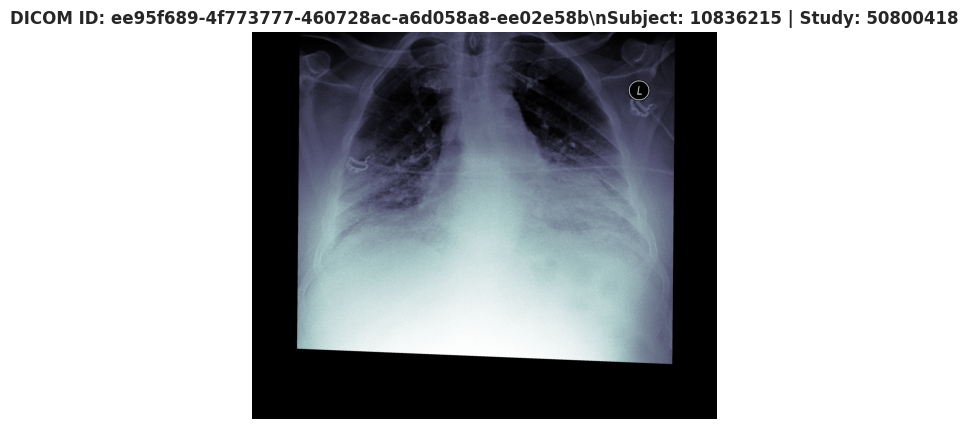

GROUND TRUTH RADIOLOGIST IMPRESSION:
--------------------------------------------------------------------------------
1. Bibasilar opacities raise concern for infection. 2. Epidural abscess cannot be excluded on this study as it is inappropriate for evaluation of such and if clinical concern, mri would be the study of choice.
--------------------------------------------------------------------------------
CHEXPERT PATHOLOGY LABELS PRESENT:
Lung Opacity
\n


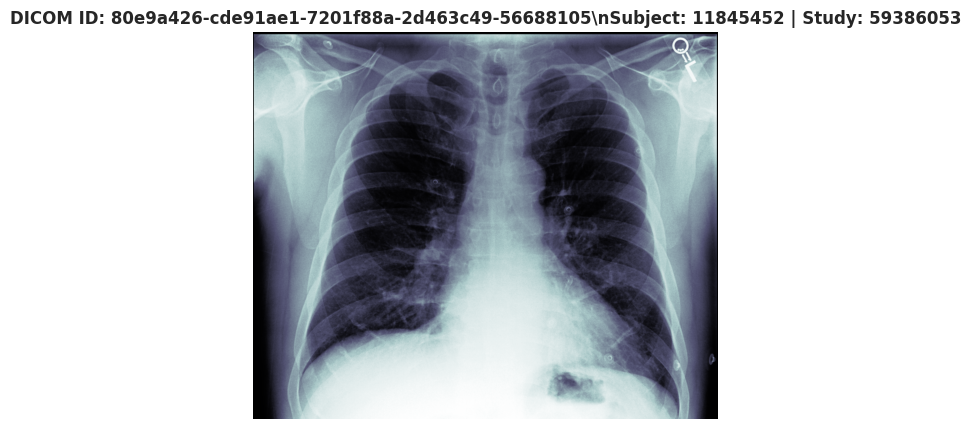

GROUND TRUTH RADIOLOGIST IMPRESSION:
--------------------------------------------------------------------------------
No acute cardiopulmonary process.
--------------------------------------------------------------------------------
CHEXPERT PATHOLOGY LABELS PRESENT:
No Finding
\n


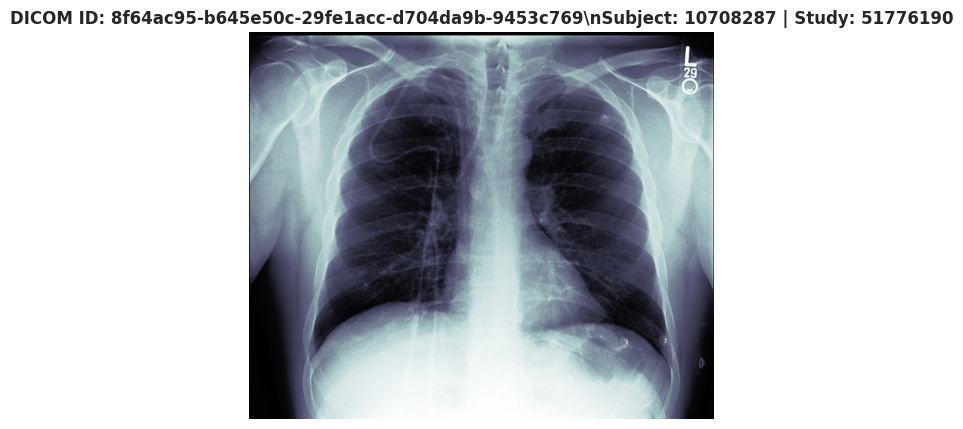

GROUND TRUTH RADIOLOGIST IMPRESSION:
--------------------------------------------------------------------------------
No acute cardiopulmonary process.
--------------------------------------------------------------------------------
CHEXPERT PATHOLOGY LABELS PRESENT:
No Finding
\n


In [9]:
# -------------------------------------------------------------------------
# 5. Visualizing Sample Case Studies (Image + Diagnosis + Report)
# -------------------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

valid_images_df = merged_df.dropna(subset=["image_path"])

if len(valid_images_df) > 0:
    np.random.seed(15)
    random_indices = np.random.choice(len(valid_images_df), min(3, len(valid_images_df)), replace=False)

    for sample_idx in random_indices:
        row = valid_images_df.iloc[sample_idx]
        image_path = row["image_path"]
        
        # Extract diagnoses
        labels_present = [col for col in chex_label_cols if row[col] == 1.0]
        if not labels_present:
            labels_present = ["No Finding (Healthy)"]
            
        img = Image.open(image_path).convert("L")
        
        plt.figure(figsize=(6, 6))
        plt.imshow(img, cmap="bone")
        plt.axis("off")
        plt.title(f"DICOM ID: {row['dicom_id']}\\nSubject: {row['subject_id']} | Study: {row['study_id']}", fontweight='bold')
        plt.show()
        
        print("=" * 80)
        print("GROUND TRUTH RADIOLOGIST IMPRESSION:")
        print("-" * 80)
        print(row["report"])
        print("-" * 80)
        print("CHEXPERT PATHOLOGY LABELS PRESENT:")
        print(", ".join(labels_present))
        print("=" * 80)
        print("\\n")
else:
    print("No chest X-ray images detected in /kaggle/input/. Attach image datasets to display sample images.")

Loading TorchXRayVision DenseNet-121 model...
If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/mimic_ch-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt -O /root/.torchxrayvision/models_data/mimic_ch-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt`
[██████████████████████████████████████████████████]


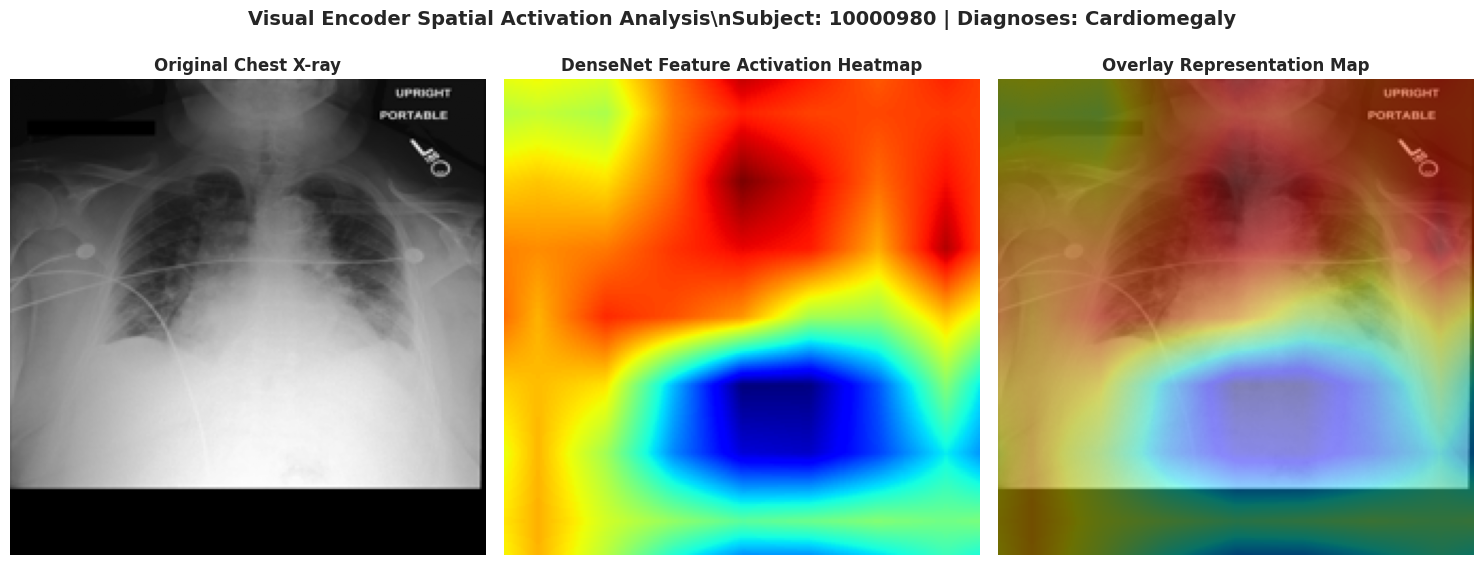

Feature Activation Map generated successfully.


In [10]:
# -------------------------------------------------------------------------
# 6. Advanced Feature: DenseNet Spatial Feature Activation Map (CAM Preview)
# -------------------------------------------------------------------------
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchxrayvision as xrv
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
from skimage.transform import resize

valid_images_df = merged_df.dropna(subset=["image_path"])

if len(valid_images_df) > 0:
    print("Loading TorchXRayVision DenseNet-121 model...")
    densenet = xrv.models.DenseNet(weights="densenet121-res224-mimic_ch")
    densenet.eval()

    # Search for a sample showing positive findings
    sample_row = None
    for idx in range(len(valid_images_df)):
        if valid_images_df.iloc[idx]["Cardiomegaly"] == 1.0:
            sample_row = valid_images_df.iloc[idx]
            break

    if sample_row is None:
        sample_row = valid_images_df.iloc[0]

    img_path = sample_row["image_path"]
    img = Image.open(img_path).convert("L").resize((224, 224))
    img_np = np.array(img, dtype=np.float32)
    img_norm = xrv.datasets.normalize(img_np, maxval=255)
    img_tensor = torch.tensor(img_norm, dtype=torch.float32).unsqueeze(0).unsqueeze(0)

    # Forward pass through encoder features
    with torch.no_grad():
        features = densenet.features(img_tensor) # Shape: [1, 1024, 7, 7]
        
    # Compute CAM average activations
    cam = features.squeeze(0).mean(dim=0).cpu().numpy() # [7, 7]
    cam = cam - np.min(cam)
    cam = cam / np.max(cam)

    cam_resized = resize(cam, (224, 224), order=1, preserve_range=True)

    # Plotting original Chest X-ray and CAM overlay
    fig, axes = plt.subplots(1, 3, figsize=(15, 6))

    axes[0].imshow(img_np, cmap="gray")
    axes[0].set_title("Original Chest X-ray", fontweight='bold')
    axes[0].axis("off")

    axes[1].imshow(cam_resized, cmap="jet")
    axes[1].set_title("DenseNet Feature Activation Heatmap", fontweight='bold')
    axes[1].axis("off")

    # Overlay
    axes[2].imshow(img_np, cmap="gray")
    axes[2].imshow(cam_resized, cmap="jet", alpha=0.45)
    axes[2].set_title("Overlay Representation Map", fontweight='bold')
    axes[2].axis("off")

    plt.suptitle(f"Visual Encoder Spatial Activation Analysis\\nSubject: {sample_row['subject_id']} | Diagnoses: Cardiomegaly", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig("visual_encoder_cam.png", dpi=300)
    plt.show()

    print("Feature Activation Map generated successfully.")
else:
    print("No chest X-ray images detected in /kaggle/input/. Attach image datasets to run activation maps.")